<a href="https://colab.research.google.com/github/naveen-pixel07/ML_2/blob/K_Means/K_Means.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

,Study Hours,IQ
0,17.407327,109.965025
1,5.192244,125.079784
2,4.788064,88.162056
3,2.892291,86.632610
4,4.026080,93.398578


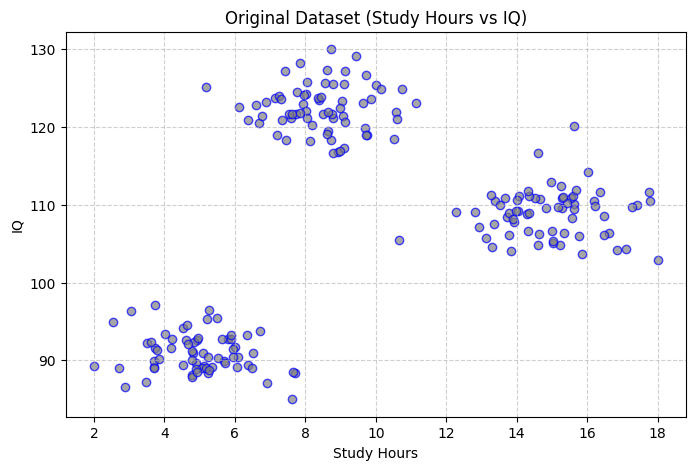

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# 1. Generate a synthetic dataset (at least 200 data points)
# We'll create 3 clusters representing different student profiles
X, y = make_blobs(n_samples=200, centers=3, cluster_std=1.5, random_state=42)

# Scale the synthetic data to match realistic ranges for Study Hours (e.g., 1-20 hrs/week) and IQ (e.g., 85-130)
study_hours = np.interp(X[:, 0], (X[:, 0].min(), X[:, 0].max()), (2, 18))
iq = np.interp(X[:, 1], (X[:, 1].min(), X[:, 1].max()), (85, 130))

# Create a DataFrame
df = pd.DataFrame({
    'Study Hours': study_hours,
    'IQ': iq
})

# Display the first few rows
display(df.head())

# Plot original data points
plt.figure(figsize=(8, 5))
plt.scatter(df['Study Hours'], df['IQ'], c='gray', alpha=0.7, edgecolors='b')
plt.title('Original Dataset (Study Hours vs IQ)')
plt.xlabel('Study Hours')
plt.ylabel('IQ')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

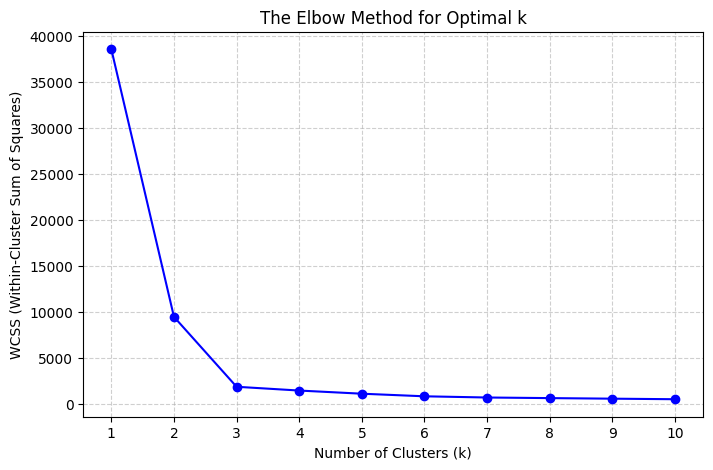

In [7]:
wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(df)
    wcss.append(kmeans.inertia_)

# Plot the WCSS values to find the "Elbow"
plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='-', color='b')
plt.title('The Elbow Method for Optimal k')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS (Within-Cluster Sum of Squares)')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

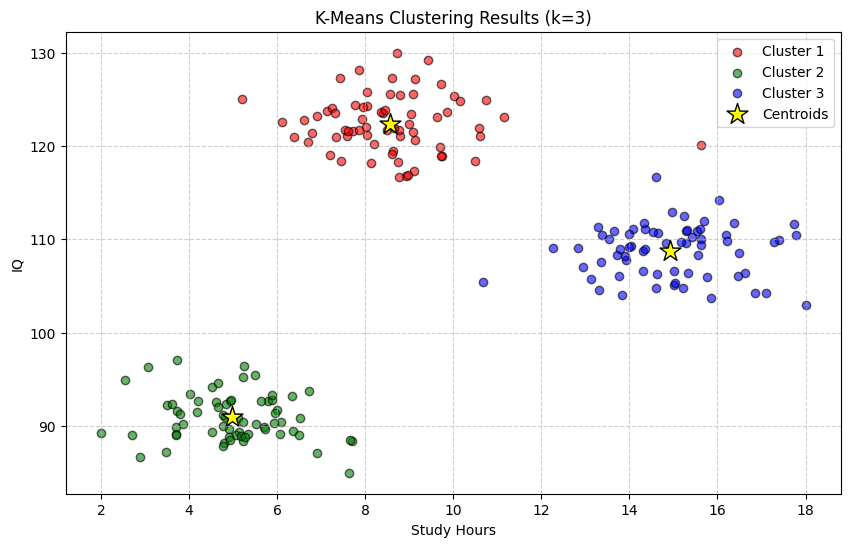

In [8]:
# Apply KMeans with optimal k=3
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(df[['Study Hours', 'IQ']])

# Get centroids
centroids = kmeans.cluster_centers_

# Visualise the clustered data
plt.figure(figsize=(10, 6))
colors = ['red', 'green', 'blue']

for cluster_id in range(optimal_k):
    cluster_data = df[df['Cluster'] == cluster_id]
    plt.scatter(cluster_data['Study Hours'], cluster_data['IQ'],
                color=colors[cluster_id], label=f'Cluster {cluster_id + 1}', alpha=0.6, edgecolors='black')

# Plot Centroids
plt.scatter(centroids[:, 0], centroids[:, 1], s=250, c='yellow', marker='*',
            edgecolors='black', label='Centroids')

plt.title('K-Means Clustering Results (k=3)')
plt.xlabel('Study Hours')
plt.ylabel('IQ')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()